# 01 - Análisis exploratorio (EDA)

**Objetivo:** entender la estructura del dataset IEEE-CIS, el desbalance, los nulos y el comportamiento del fraude en el tiempo, antes de modelar.

In [13]:
import sys
sys.path.append("..")  # para importar src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_ieee, save_processed

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

## 1. Carga y merge
Se usa un *left join* porque no todas las transacciones tienen información de identidad.

In [14]:
df = load_ieee("../data/raw")
df.head()

Cargando train_transaction.csv ...
Memoria: 1791.7 MB -> 932.8 MB (48% menos)
Cargando train_identity.csv ...
Memoria: 56.5 MB -> 43.3 MB (23% menos)
Dataset final: 590,540 filas x 435 columnas


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,...,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,has_identity
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0,19.0,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,2.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0,287.0,NaN,outlook.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0,NaN,NaN,yahoo.com,NaN,2.0,5.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,25.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0,NaN,NaN,gmail.com,NaN,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,NotFound,NaN,-480.0,New,NotFound,166.0,NaN,542.0,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,1


In [15]:
# Guardamos en parquet para no volver a leer los CSV 
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
df.to_parquet("../data/processed/train_merged.parquet", index=False)

## 2. Visión general

In [16]:
df.shape, df.dtypes.value_counts()

((590540, 435),
 float32    399
 str         31
 int32        2
 int8         2
 int16        1
 Name: count, dtype: int64)

## 3. Variable objetivo y desbalance

Tasa de fraude: 3.50%  |  Casos de fraude: 20,663


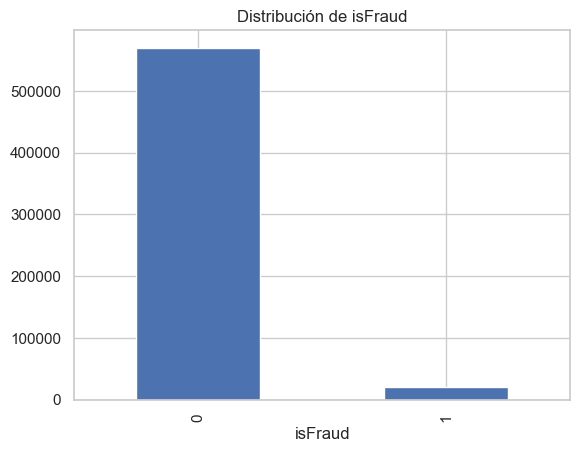

In [17]:
fraud_rate = df["isFraud"].mean()
print(f"Tasa de fraude: {fraud_rate:.2%}  |  Casos de fraude: {df['isFraud'].sum():,}")
df["isFraud"].value_counts().plot(kind="bar", title="Distribución de isFraud")
plt.show()

## 4. Valores nulos

In [18]:
null_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(f"Columnas con >50% de nulos: {(null_pct > 50).sum()} de {df.shape[1]}")
null_pct.head(25)

Columnas con >50% de nulos: 214 de 435


id_24    99.196159
id_25    99.130965
id_07    99.127070
id_08    99.127070
id_21    99.126393
id_26    99.125715
id_27    99.124699
id_23    99.124699
id_22    99.124699
dist2    93.628374
D7       93.409930
id_18    92.360721
D13      89.509263
D14      89.469469
D12      89.041047
id_04    88.768923
id_03    88.768923
D6       87.606767
id_33    87.589494
id_09    87.312290
D8       87.312290
id_10    87.312290
D9       87.312290
id_30    86.865411
id_32    86.861855
dtype: float64

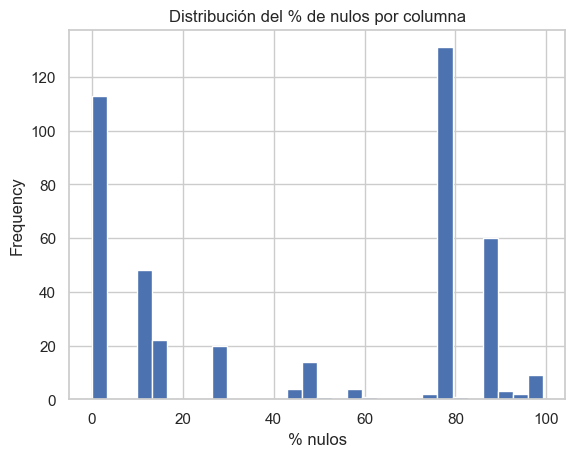

In [19]:
null_pct.plot(kind="hist", bins=30, title="Distribución del % de nulos por columna")
plt.xlabel("% nulos"); plt.show()

## 5. Monto de la transacción (`TransactionAmt`)

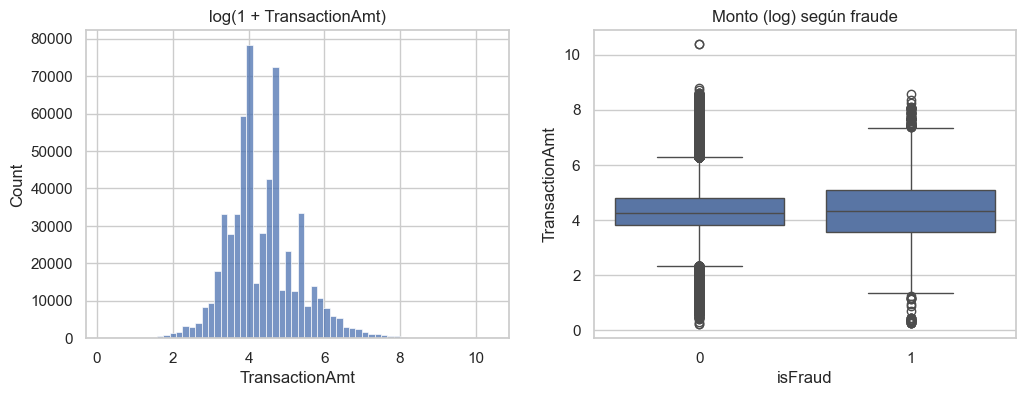

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,569877.0,134.511658,239.395081,0.251,43.970001,68.5,120.0,31937.390625
1,20663.0,149.244766,232.212158,0.292,35.043999,75.0,161.0,5191.000000


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(df["TransactionAmt"]), bins=60, ax=ax[0])
ax[0].set_title("log(1 + TransactionAmt)")
sns.boxplot(data=df, x="isFraud", y=np.log1p(df["TransactionAmt"]), ax=ax[1])
ax[1].set_title("Monto (log) según fraude")
plt.show()
df.groupby("isFraud")["TransactionAmt"].describe()

## 6. Fraude en el tiempo
`TransactionDT` son segundos desde un punto de referencia **desconocido**, por lo que sólo podemos hablar de días y horas relativos.

C:\Users\Carlos\AppData\Local\Temp\ipykernel_3256\3553062807.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["day"] = df["TransactionDT"] // (24 * 3600)
C:\Users\Carlos\AppData\Local\Temp\ipykernel_3256\3553062807.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["hour"] = (df["TransactionDT"] // 3600) % 24


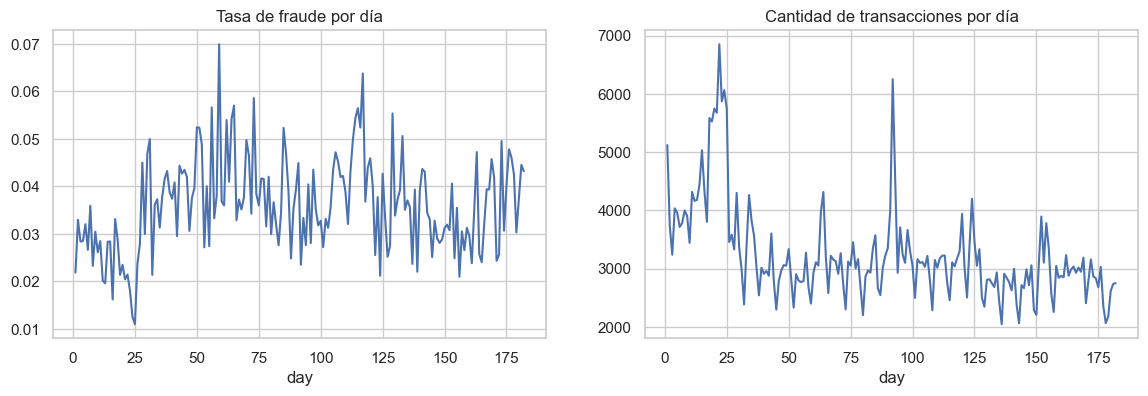

In [21]:
df["day"] = df["TransactionDT"] // (24 * 3600)
df["hour"] = (df["TransactionDT"] // 3600) % 24

daily = df.groupby("day")["isFraud"].agg(["mean", "size"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
daily["mean"].plot(ax=ax[0], title="Tasa de fraude por día")
daily["size"].plot(ax=ax[1], title="Cantidad de transacciones por día")
plt.show()

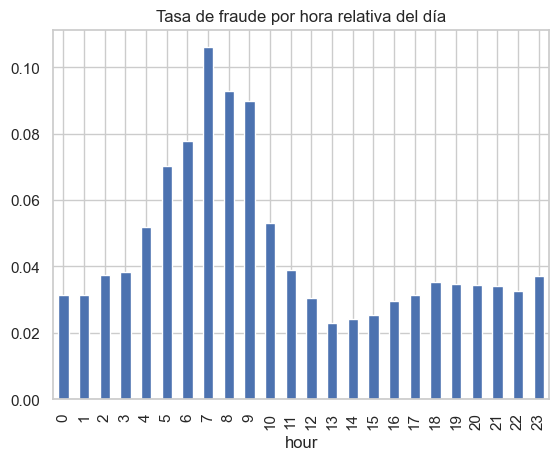

In [22]:
df.groupby("hour")["isFraud"].mean().plot(kind="bar", title="Tasa de fraude por hora relativa del día")
plt.show()

## 7. Variables categóricas clave

In [23]:
for col in ["ProductCD", "card4", "card6", "DeviceType"]:
    print(df.groupby(col, observed=True)["isFraud"].agg(["mean", "size"]).round(4), "\n")

             mean    size
ProductCD                
C          0.1169   68519
H          0.0477   33024
R          0.0378   37699
S          0.0590   11628
W          0.0204  439670 

                    mean    size
card4                           
american express  0.0287    8328
discover          0.0773    6651
mastercard        0.0343  189217
visa              0.0348  384767 

                   mean    size
card6                          
charge card      0.0000      15
credit           0.0668  148986
debit            0.0243  439938
debit or credit  0.0000      30 

              mean   size
DeviceType               
desktop     0.0652  85165
mobile      0.1017  55645 



## 8. ¿Importa tener información de identidad?

In [24]:
df.groupby("has_identity")["isFraud"].agg(["mean", "size"])

,mean,size
has_identity,,
0,0.020939,446307
1,0.078470,144233


## 9. Conclusiones preliminares

**Estructura y desbalance**
- El dataset tiene 590.540 transacciones y 435 columnas, con un 3,50% de fraude (20.663 casos). Está fuertemente desbalanceado, por lo que accuracy no sirve como métrica; se usará AUC-PR y análisis de costo.

**Valores nulos**
- 214 de 435 columnas tienen más de 50% de nulos. Las más vacías son las de identidad (`id_*`), `dist2` y varias columnas `D`.
- Decisión: no imputar a ciegas. Se usarán modelos que manejan nulos de forma nativa (LightGBM), ya que la ausencia del dato puede ser informativa.

**Monto (`TransactionAmt`)**
- La media es similar entre clases (134 no fraude vs 149 fraude), pero el fraude es más disperso: percentil 25 más bajo (35 vs 44) y percentil 75 más alto (161 vs 120).
- El monto por sí solo no separa bien las clases. Hay un outlier de ~32.000 en no fraude.

**Variables categóricas**
- `ProductCD` es muy discriminante: C tiene 11,7% de fraude y W solo 2,0%, aunque W concentra el 74% de las transacciones.

**Identidad**
- Solo ~24% de las transacciones tiene información de identidad, pero su tasa de fraude es de 7,85% contra 2,09% sin identidad (casi 4 veces mayor).
- `has_identity` es una señal útil, pero no causal: probablemente refleja flujos de compra distintos. Hay que verificar que se mantenga estable en el tiempo.

**Temporalidad**
- Los datos cubren ~180 días relativos (la fecha real de origen es desconocida).
- La tasa de fraude diaria es ruidosa y muestra picos alrededor de los días ~60 y ~120. Hay horas relativas con tasa más alta, con pico en la hora 7, y con una magnitud notablemente más alta que el resto del día entre las 4 y las 10.
- Implicancia: la validación debe ser temporal y los cortes deben considerar los picos.

**Próximos pasos**
- Definir cortes temporales (notebook 02), armar un baseline y trabajar el feature engineering.